<a href="https://colab.research.google.com/github/MarcGaac/EDA-DSC1105/blob/main/DSC1105_SA_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

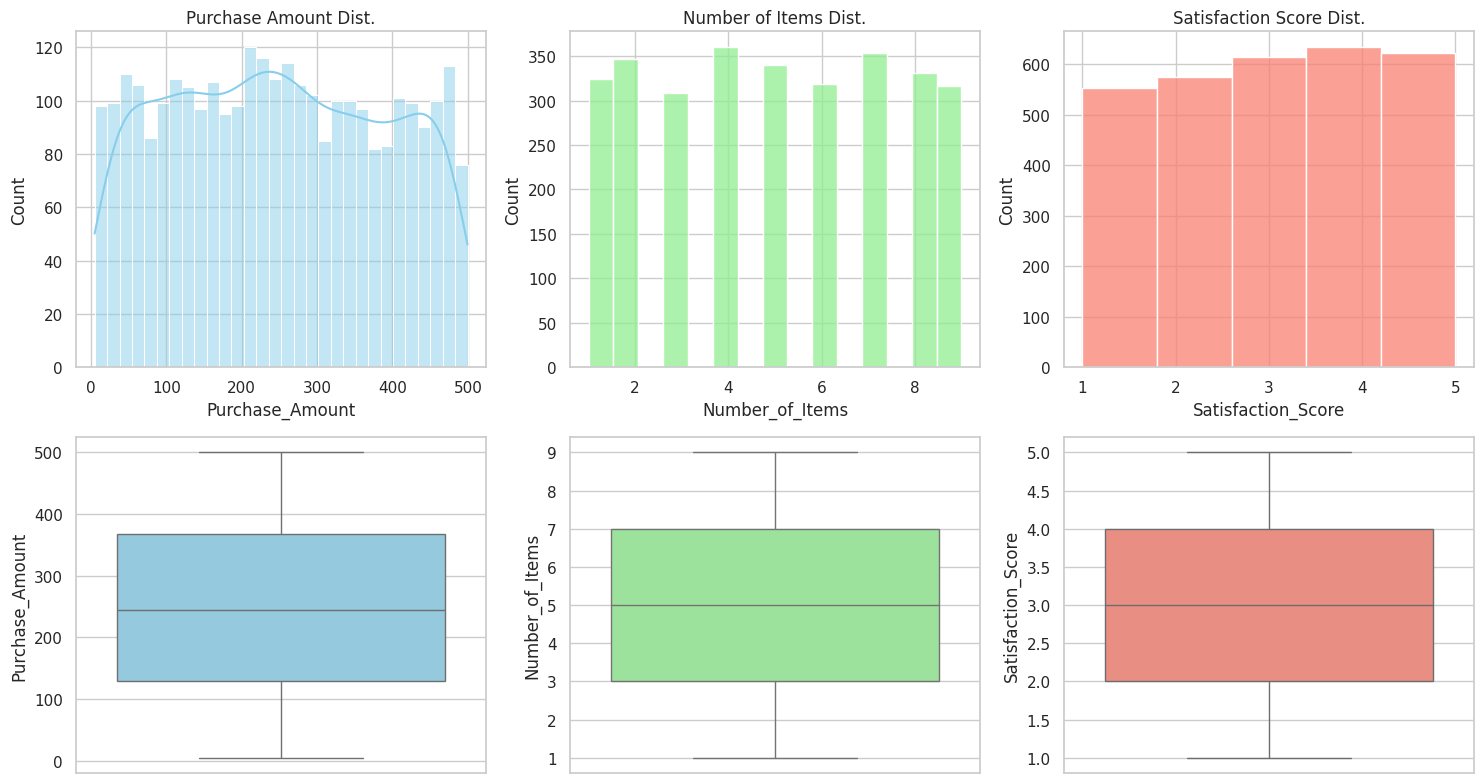

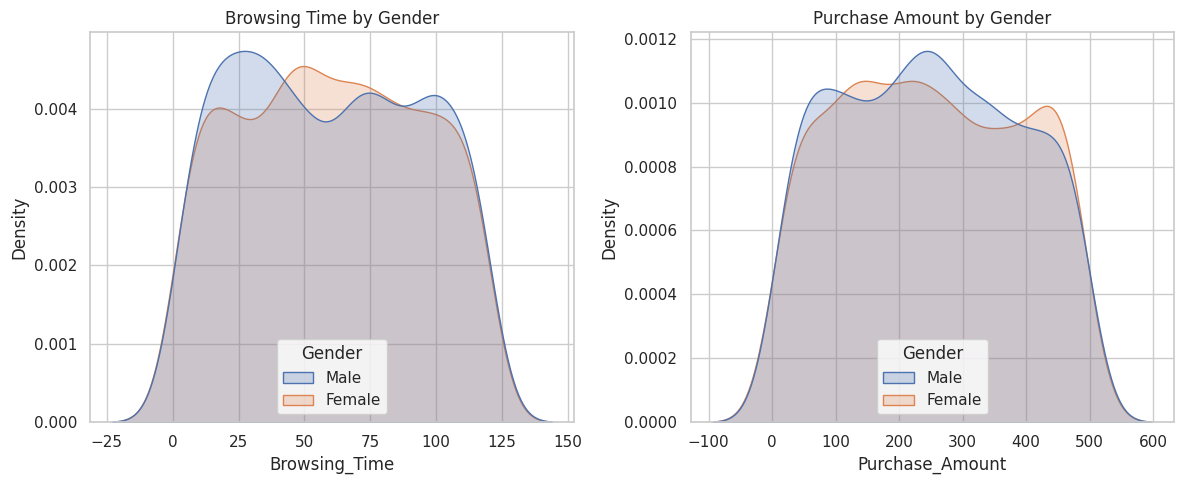

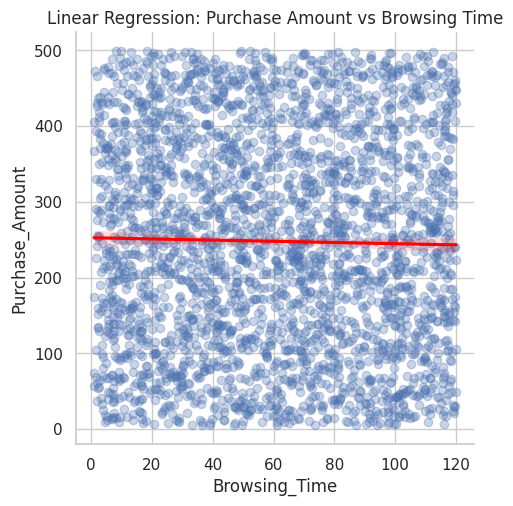

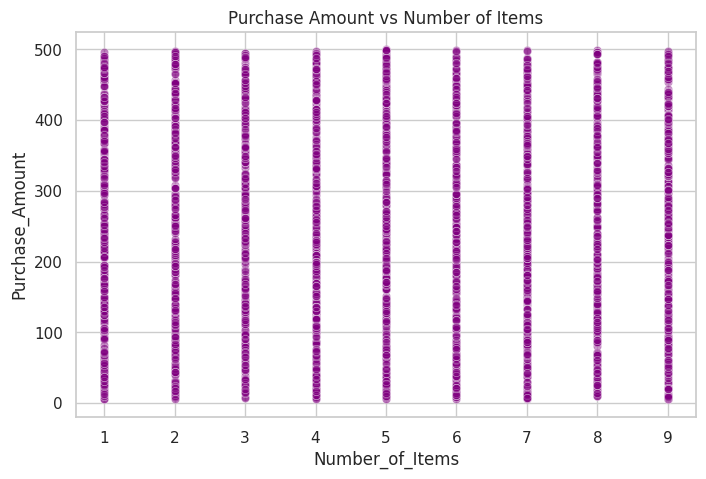

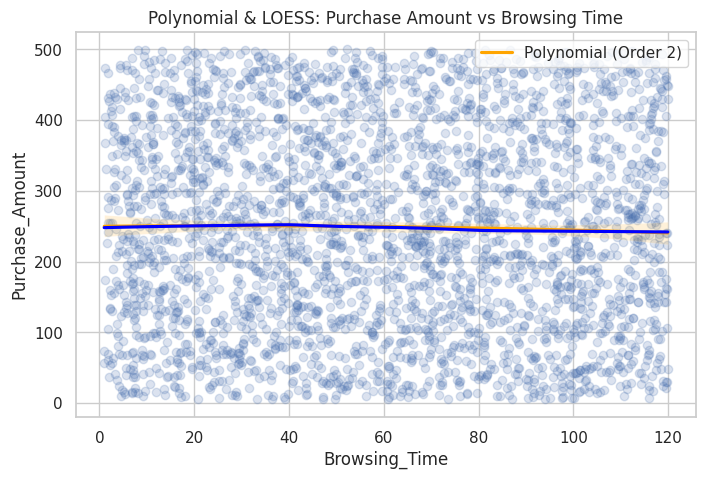

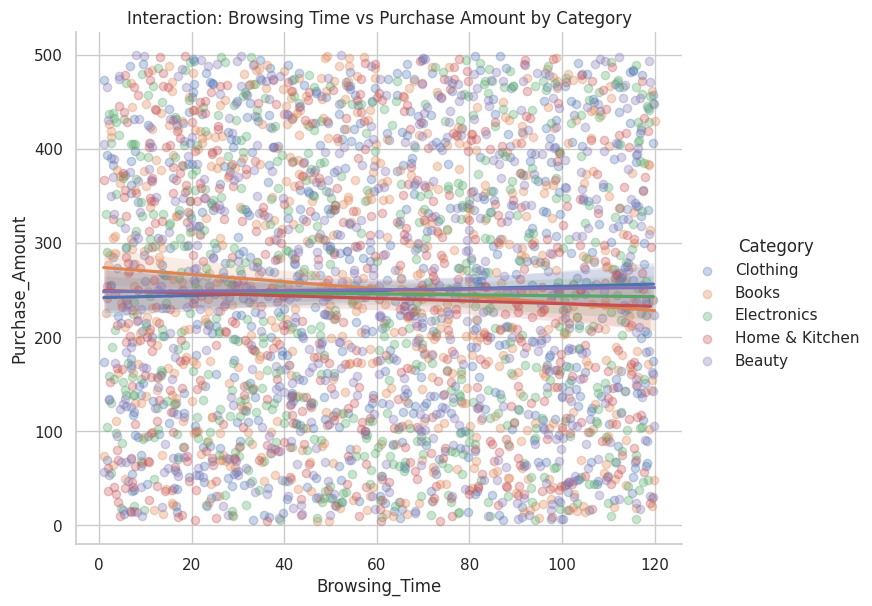

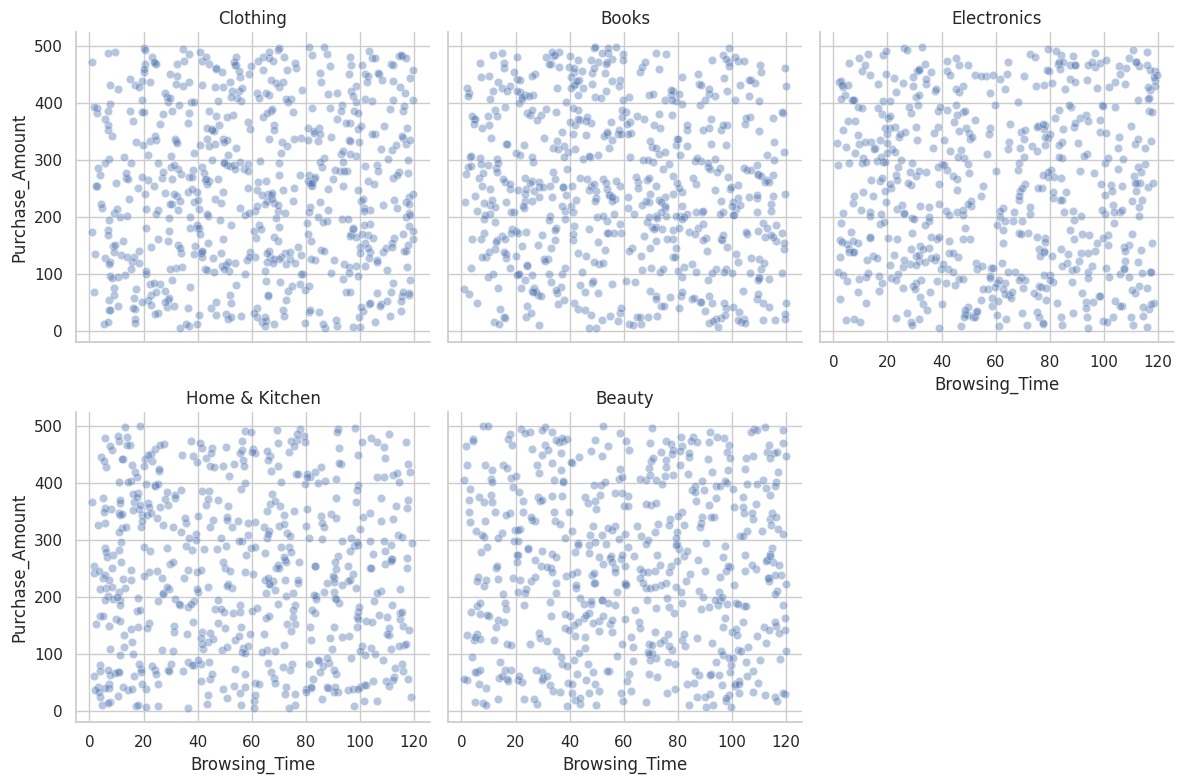

--- Multiple Regression Output ---
                            OLS Regression Results                            
Dep. Variable:        Purchase_Amount   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.7928
Date:                Thu, 08 Oct 2026   Prob (F-statistic):              0.498
Time:                        01:52:44   Log-Likelihood:                -19099.
No. Observations:                3000   AIC:                         3.821e+04
Df Residuals:                    2996   BIC:                         3.823e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
I

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load the dataset
file_path = "EDA_Ecommerce_Assessment_11036599.xlsx"
df = pd.read_excel(file_path)

# Set plotting style
sns.set_theme(style="whitegrid")

# ==========================================
# UNIT 1: Univariate Data Analysis
# ==========================================

# 1. Histograms and Boxplots
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(df['Purchase_Amount'], bins=30, kde=True, ax=axes[0,0], color='skyblue').set_title("Purchase Amount Dist.")
sns.histplot(df['Number_of_Items'], bins=15, kde=False, ax=axes[0,1], color='lightgreen').set_title("Number of Items Dist.")
sns.histplot(df['Satisfaction_Score'], bins=5, kde=False, ax=axes[0,2], color='salmon').set_title("Satisfaction Score Dist.")

sns.boxplot(y=df['Purchase_Amount'], ax=axes[1,0], color='skyblue')
sns.boxplot(y=df['Number_of_Items'], ax=axes[1,1], color='lightgreen')
sns.boxplot(y=df['Satisfaction_Score'], ax=axes[1,2], color='salmon')
plt.tight_layout()
plt.show()

# 2. Density Plots by Gender
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.kdeplot(data=df, x='Browsing_Time', hue='Gender', fill=True, ax=axes[0]).set_title("Browsing Time by Gender")
sns.kdeplot(data=df, x='Purchase_Amount', hue='Gender', fill=True, ax=axes[1]).set_title("Purchase Amount by Gender")
plt.tight_layout()
plt.show()

# 3. Simple Linear Regression Plot
sns.lmplot(data=df, x='Browsing_Time', y='Purchase_Amount', scatter_kws={'alpha':0.3}, line_kws={'color':'red'})
plt.title("Linear Regression: Purchase Amount vs Browsing Time")
plt.show()

# ==========================================
# UNIT 2: Bivariate Data Analysis
# ==========================================

# 1. Scatter Plot: Purchase Amount vs Number of Items
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Number_of_Items', y='Purchase_Amount', alpha=0.5, color='purple')
plt.title("Purchase Amount vs Number of Items")
plt.show()

# 2. Polynomial Regression vs Simple Linear Plot (LOESS)
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x='Browsing_Time', y='Purchase_Amount', order=2, scatter_kws={'alpha':0.2},
            line_kws={'color':'orange', 'label':'Polynomial (Order 2)'})
sns.regplot(data=df, x='Browsing_Time', y='Purchase_Amount', lowess=True, scatter=False,
            line_kws={'color':'blue', 'label':'LOESS'})
plt.legend()
plt.title("Polynomial & LOESS: Purchase Amount vs Browsing Time")
plt.show()

# ==========================================
# UNIT 3: Trivariate/Hypervariate Data Analysis
# ==========================================

# 1. Interaction Plot: Browsing Time vs Purchase Amount by Category
sns.lmplot(data=df, x='Browsing_Time', y='Purchase_Amount', hue='Category', height=6, aspect=1.2, scatter_kws={'alpha':0.3})
plt.title("Interaction: Browsing Time vs Purchase Amount by Category")
plt.show()

# 2. Coplots (FacetGrid)
g = sns.FacetGrid(df, col="Category", col_wrap=3, height=4)
g.map_dataframe(sns.scatterplot, x="Browsing_Time", y="Purchase_Amount", alpha=0.4)
g.set_titles(col_template="{col_name}")
plt.show()

# 3. Multiple Regression Model (Statsmodels)
print("--- Multiple Regression Output ---")
model = smf.ols('Purchase_Amount ~ Browsing_Time + Number_of_Items + Satisfaction_Score', data=df).fit()
print(model.summary())


**​Unit 1: Univariate Data Analysis**


​Data Distribution & Central Tendency:
An analysis of the 3,000 customer records reveals that the Purchase_Amount has a mean of $247.96 and a median of $245.09. Because the mean and median are closely aligned, the data is roughly symmetric. The variance is 19,845.99 with a standard deviation of $140.88, and an interquartile range (IQR) of 238.50, indicating a wide and relatively uniform spread of purchase amounts across the customer base.


Gender Density Comparison:
Density plots reveal that male and female shoppers exhibit nearly identical distributions for both Browsing_Time and Purchase_Amount. There is no significant gender-based divergence in time spent on the site or money spent at checkout.


​Transformations & Skewness:
The original Browsing_Time variable is highly symmetric with a skewness of 0.0386. Applying a logarithmic transformation actually over-corrected the data, shifting the skewness to -1.219 (heavily left-skewed), while a square root transformation resulted in a skewness of -0.477. Since the original data was already normally distributed, the transformations were unnecessary and reduced data normality.


​Simple Linear Regression:
A simple linear regression predicting Purchase_Amount based on Browsing_Time yields a slope of -0.0784. However, the p-value is 0.296, which is well above the 0.05 significance threshold. This indicates that there is no statistically significant linear relationship between how long a customer browses and how much they spend.

**Unit 2: Bivariate Data Analysis**


​Polynomial Regression and Robust Regression:


Due to the linear model indicating no correlation, a polynomial regression (degree 2) was performed in order to examine the presence of a non-linear, curved correlation (for instance, one where spending grows until it peaks after some browsing time). Polynomial coefficients returned high p-values (x = 0.0647, x² = -0.0012) which indicate that no curved relationship was identified again. Results of the LOESS smoothing curve visually verified this data, with the LOESS curve giving a straight line across the scatter plot.


The comparison of Ordinary Least Squares (OLS) with the robust regression model (Huber’s T) showed an insignificant change in the coefficient of browsing time (OLS: -0.0784 vs. Robust: -0.0803), which indirectly indicates the presence of very few outliers in the data. Correlation of purchase and the number of items purchased produces a random scatter showing that purchasing a number of items does not imply a bigger total value of the cart (probably, due to substantial differences in item prices).

**Unit 3: Trivariate & Hypervariate Data Analysis**


Category Interactions:


Plots of interaction showed the relationship between browsing and purchasing behavior does not vary according to what customers buy. The regression lines for various categories (like Electronics and Clothing) were straight and therefore did not show any significant interaction effect.

Multiple Regression and Variable Importance:
Multiple regression was performed using Purchase_Amount as the response variable while the predictors were Browsing_Time, Number_of_Items, and Satisfaction_Score.

Browsing Time: p-value = 0.289

Number of Items: p-value = 0.436

Satisfaction Score: p-value = 0.402

**Conclusion:**

None of the predictor variables registered any statistical significance, and model selection criteria (including stepwise regression) would exclude all the three predictors reviewed. Therefore, we can conclude that, in this case, total transaction amount is independent of the length of browsing time, number of items purchased, and level of satisfaction after making the purchase.